# 🛒 Byte Supply — Big Data Analytics

**INTI International University · Mobility Program**

End-to-end analysis of **24,991 e-commerce transactions** (October 2021 – September 2026) for *Byte Supply*, a Malaysian online retailer of electronics, accessories and office products.

| Section | What it answers |
|---|---|
| 1. Data overview | What does the dataset contain? Is it clean? |
| 2. KPI analysis | How is the business performing overall and year by year? |
| 3. Required visualisations | Revenue trend · Category performance · Rating distribution |
| 4. Additional visualisations | Seasonality · Shopping hours · Payment mix · Delivery vs satisfaction |
| 5. Insight calculations | The numbers behind the business recommendations |
| 6. Machine learning | Linear vs Polynomial regression on monthly revenue |
| 7. Forecast | Next 12 months of revenue |
| 8. Recommendations | What Byte Supply should do next |

> All reusable logic lives in [`src/byte_supply`](../src/byte_supply); this notebook tells the story.
> The dataset is **synthetic** and is used to demonstrate the analytics workflow.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import display

from byte_supply import plots
from byte_supply.data import load_transactions, prepare, data_dictionary
from byte_supply.kpis import (overall_kpis, business_year_kpis, category_summary,
                              segment_summary, insight_metrics)
from byte_supply.forecasting import build_monthly_frame, compare_models, forecast_next_months

pd.set_option("display.float_format", "{:,.2f}".format)
plots.set_style()

df = prepare(load_transactions(ROOT / "data" / "byte_supply_transactions.csv"))
print(f"Loaded {len(df):,} rows × {df.shape[1]} columns")
df.head()

Loaded 24,991 rows × 37 columns


,Transaction_ID,Date_Time,Date,Year,Month,Day,Hour,Day_of_Week,Is_Campaign_Day,Customer_ID,...,Stock_Out_Flag,Promised_Delivery_Days,Actual_Delivery_Days,Delivery_Status,Rating,YearMonth,Quarter,Business_Year,Is_Mega_Sale,Is_Late
0,TXN-0000001,2021-10-01 12:03:12,2021-10-01,2021,10,1,12,Friday,0,C000001,...,0,2,2,On-time,NaN,2021-10,2021Q4,1,False,False
1,TXN-0000002,2021-10-01 15:58:27,2021-10-01,2021,10,1,15,Friday,0,C000002,...,0,3,3,On-time,NaN,2021-10,2021Q4,1,False,False
2,TXN-0000003,2021-10-01 16:51:25,2021-10-01,2021,10,1,16,Friday,0,C000001,...,0,2,2,On-time,NaN,2021-10,2021Q4,1,False,False
3,TXN-0000004,2021-10-01 16:55:56,2021-10-01,2021,10,1,16,Friday,0,C000003,...,0,5,5,On-time,NaN,2021-10,2021Q4,1,False,False
4,TXN-0000005,2021-10-01 18:48:12,2021-10-01,2021,10,1,18,Friday,0,C000004,...,0,3,3,On-time,NaN,2021-10,2021Q4,1,False,False


## 1. Data Overview & Preparation

`prepare()` parses timestamps and adds helper fields:

- **`YearMonth` / `Quarter`** – periods for time-series aggregation
- **`Business_Year`** – 1 → 5, each running **October → September**
- **`Is_Mega_Sale`** – the 9.9, 10.10, 11.11 and 12.12 shopping festivals
- **`Is_Late`** – late-delivery flag

Missing customer ratings are **kept as missing** (not every customer leaves a review) rather than imputed.

In [2]:
data_dictionary(df)

,dtype,missing,missing_pct,unique,example
Transaction_ID,str,0,0.00,24991,TXN-0000001
Date_Time,datetime64[us],0,0.00,24988,2021-10-01 12:03:12
Date,str,0,0.00,1826,2021-10-01
Year,int64,0,0.00,6,2021
Month,int64,0,0.00,12,10
Day,int64,0,0.00,31,1
Hour,int64,0,0.00,24,12
Day_of_Week,str,0,0.00,7,Friday
Is_Campaign_Day,int64,0,0.00,2,0
Customer_ID,str,0,0.00,17863,C000001


## 2. KPI Analysis

### 2.1 Headline KPIs (full five-year period)

In [3]:
overall_kpis(df).to_frame("Value")

,Value
Total revenue (RM),"2,041,059.71"
Number of orders,"24,991.00"
Unique customers,"17,863.00"
Average order value (RM),81.67
Gross profit (RM),"743,987.39"
Gross margin (%),36.45
Average rating (rated orders),4.02
Rated orders (%),58.29
On-time delivery rate (%),89.62
Stock-out rate (%),2.70


### 2.2 KPIs by business year

In [4]:
by_year = business_year_kpis(df)
by_year.style.format("{:,.2f}").background_gradient(subset=["Revenue", "Revenue_Growth_Pct"], cmap="Blues")

,Orders,Revenue,Gross_Profit,Avg_Rating,On_Time_Pct,Stock_Out_Pct,AOV,Revenue_Growth_Pct,Margin_Pct
Business_Year,,,,,,,,,
1,"3,611.00","280,235.82","102,214.14",3.95,85.77,4.02,77.61,nan,36.47
2,"4,244.00","341,189.73","123,851.48",4.00,88.38,3.02,80.39,21.75,36.30
3,"4,746.00","382,749.54","139,631.36",3.97,88.54,3.20,80.65,12.18,36.48
4,"5,572.00","463,602.04","168,748.36",4.05,90.99,2.42,83.20,21.12,36.40
5,"6,818.00","573,282.58","209,542.05",4.09,92.05,1.67,84.08,23.66,36.55


**Reading the table:** revenue more than doubled from Year 1 to Year 5, while AOV, on-time delivery and ratings all trended up and stock-outs fell from ~4% to ~1.7%. Gross margin stayed remarkably stable at ~36.5% — growth came from **volume**, not price.

## 3. Required Visualisations

### 3.1 Monthly revenue trend

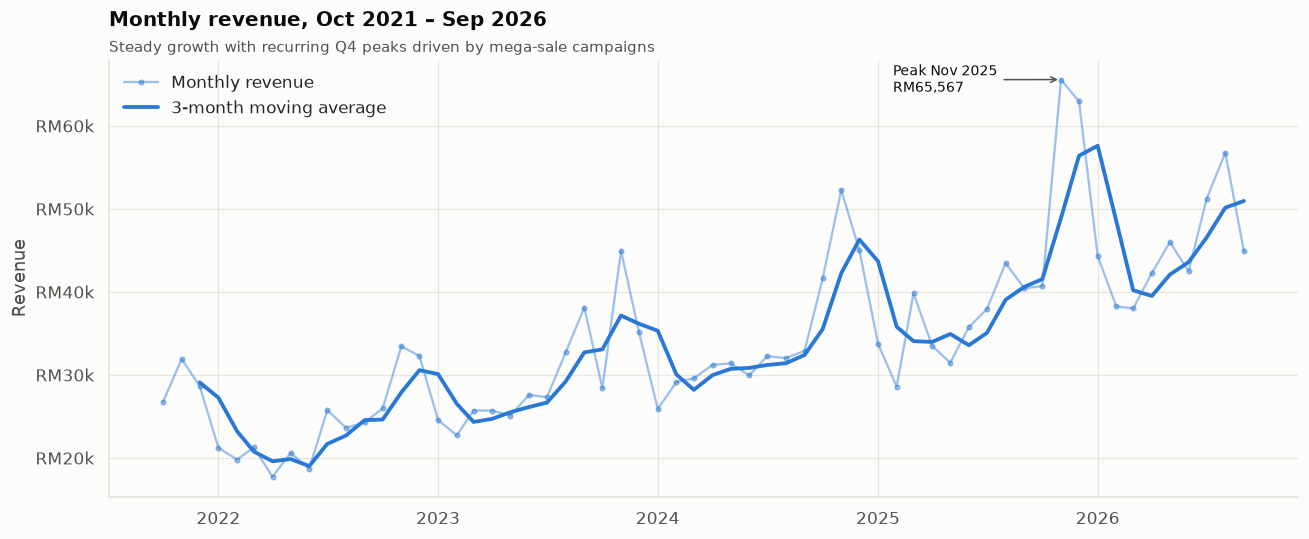

In [5]:
plots.monthly_revenue_trend(df);

### 3.2 Sales and profitability by category

,Revenue,Profit,Orders,Share_Pct,Margin_Pct
Category,,,,,
Small Electronics,"702,433.94","215,004.64",5720,34.42,30.61
Computer Peripherals,"444,763.62","153,492.97",4221,21.79,34.51
Phone Accessories,"337,291.05","147,812.45",6871,16.53,43.82
Home Office Essentials,"305,523.41","121,657.81",3358,14.97,39.82
Office Supplies,"251,047.69","106,019.52",4821,12.30,42.23


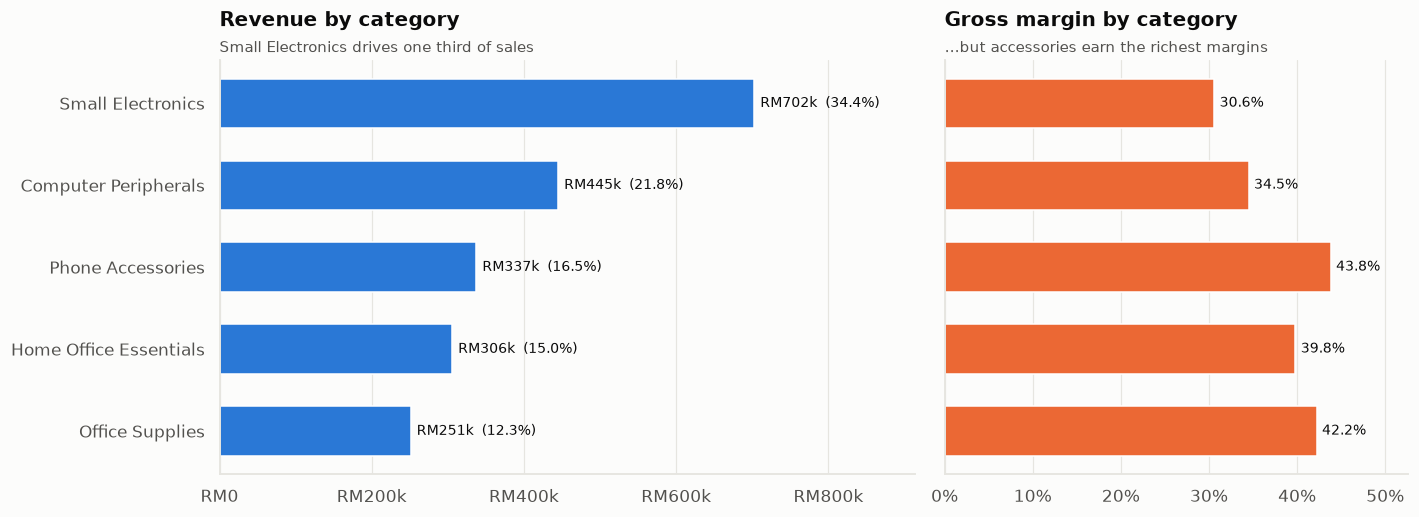

In [6]:
cat = category_summary(df)
plots.category_performance(cat)
cat

Small Electronics generates a third of revenue but has the **thinnest margin (30.6%)**. Phone Accessories and Office Supplies earn 42–44% — ideal add-on / bundle items.

### 3.3 Customer rating distribution

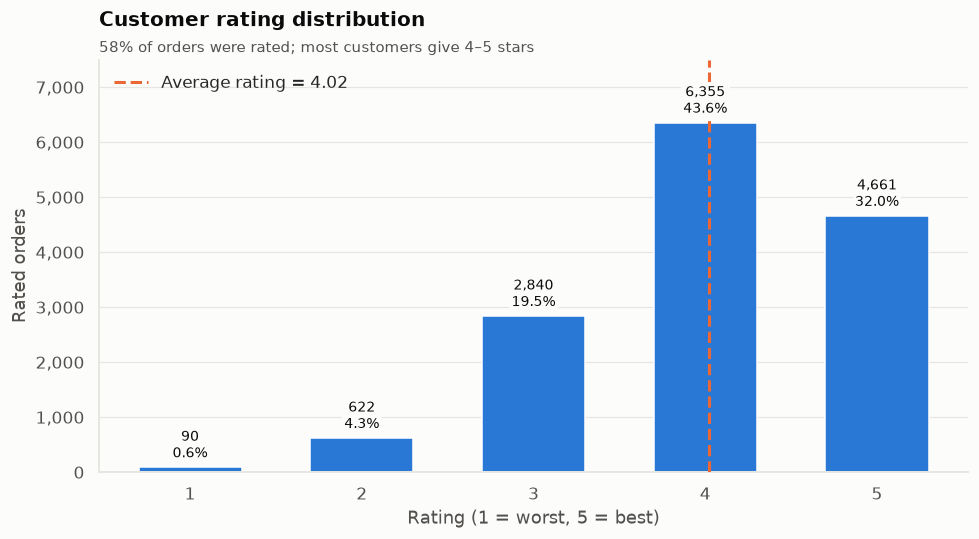

In [7]:
plots.rating_distribution(df);

## 4. Additional Visualisations

### 4.1 Seasonality — revenue by month and business year

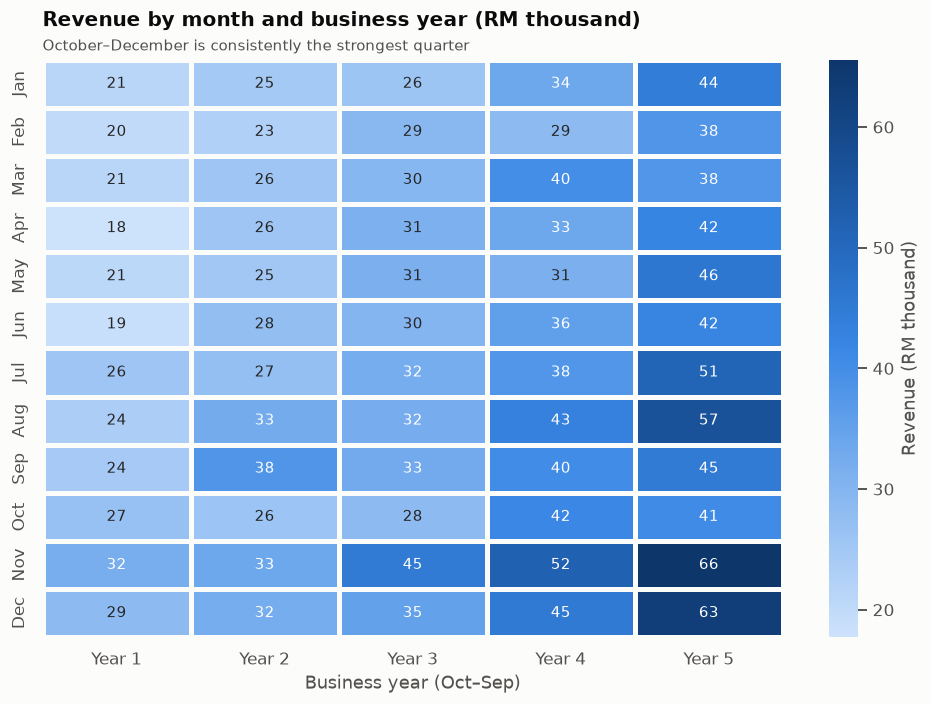

In [8]:
plots.seasonality_heatmap(df);

### 4.2 When do customers shop?

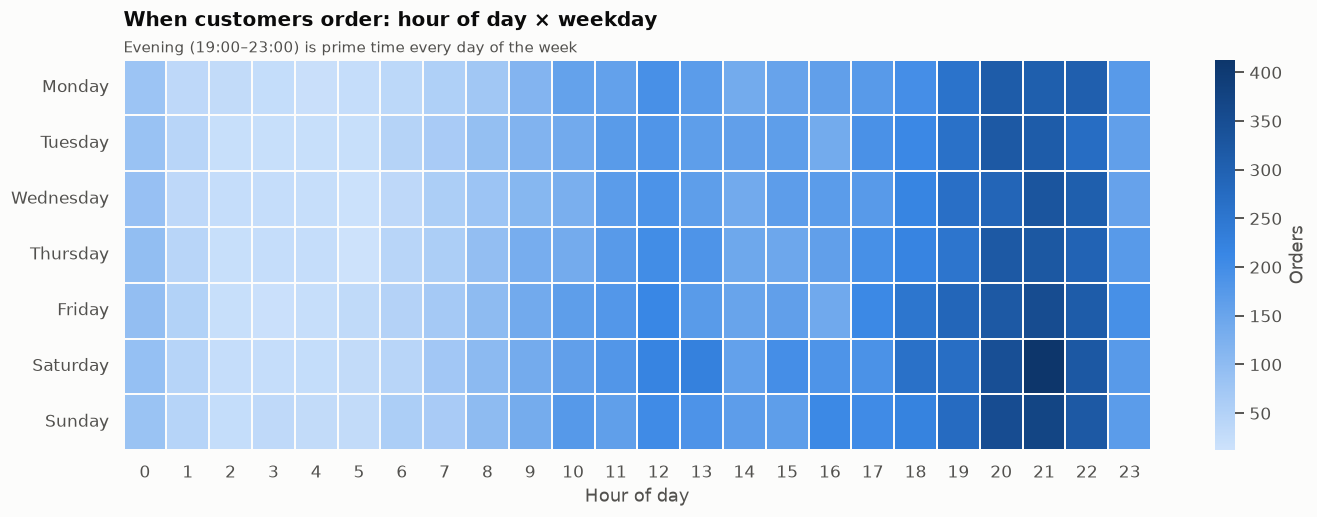

In [9]:
plots.hour_weekday_heatmap(df);

### 4.3 Payment method mix

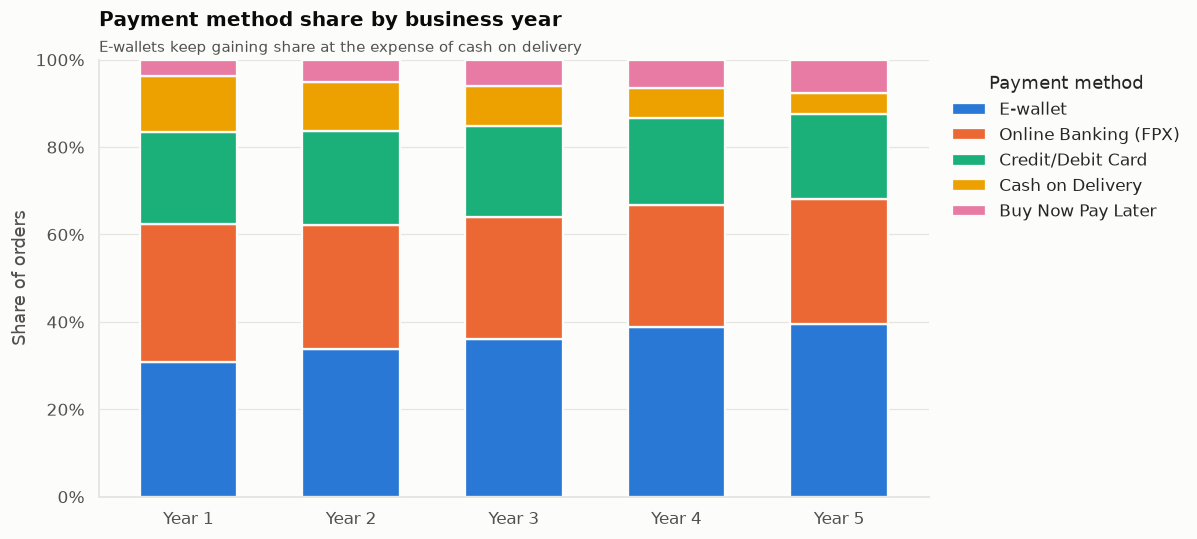

In [10]:
plots.payment_mix(df);

### 4.4 Delivery performance and customer satisfaction

Shown as two aligned panels (rather than a dual-axis chart) so each measure keeps its own honest scale.

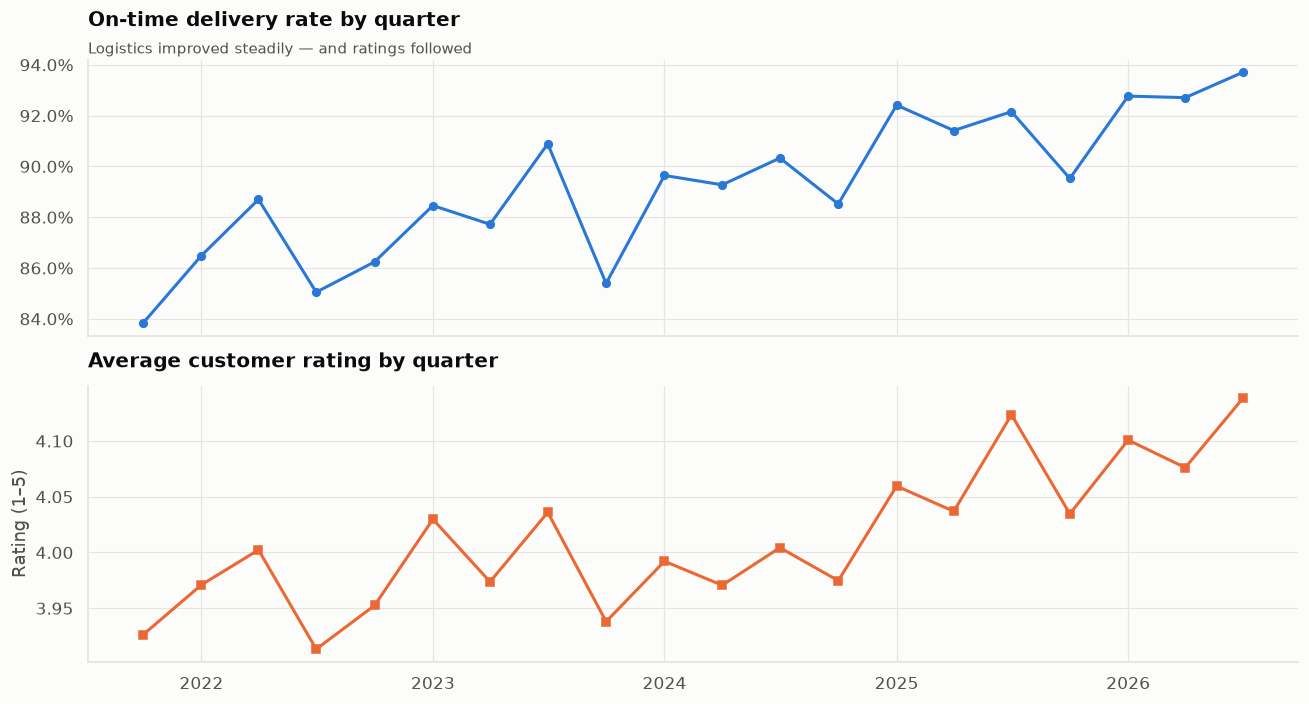

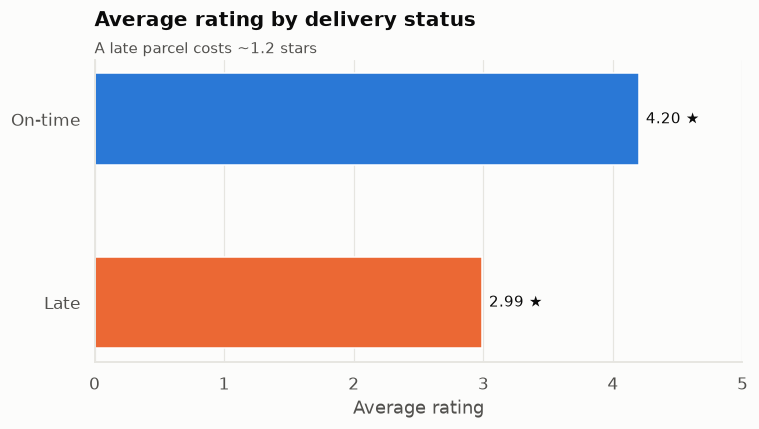

In [11]:
plots.delivery_vs_rating(df);
plots.late_delivery_impact(df);

### 4.5 Segment breakdowns

In [12]:
for col in ["Customer_Segment", "Device", "Customer_State"]:
    print(f"\n▶ {col}")
    display(segment_summary(df, col))


▶ Customer_Segment


,Orders,Revenue,Avg_Rating,On_Time_Pct,AOV,Share_Pct
Customer_Segment,,,,,,
Young Professional,10492,"826,526.50",4.02,89.60,78.78,40.49
Small Business,6073,"612,421.48",4.00,88.98,100.84,30.01
Student,8426,"602,111.73",4.04,90.09,71.46,29.50



▶ Device


,Orders,Revenue,Avg_Rating,On_Time_Pct,AOV,Share_Pct
Device,,,,,,
Mobile App,11592,"920,540.66",4.02,89.36,79.41,45.10
Mobile Web,7221,"580,695.94",4.03,89.77,80.42,28.45
Desktop,6178,"539,823.11",4.01,89.92,87.38,26.45



▶ Customer_State


,Orders,Revenue,Avg_Rating,On_Time_Pct,AOV,Share_Pct
Customer_State,,,,,,
Selangor,6762,"549,500.61",4.03,90.08,81.26,26.92
Kuala Lumpur,4541,"375,822.85",4.04,90.29,82.76,18.41
Other States,3246,"267,220.33",4.02,89.80,82.32,13.09
Johor,3026,"243,261.31",4.01,90.32,80.39,11.92
Penang,2580,"209,240.14",4.02,90.04,81.10,10.25
Sarawak,1814,"151,123.50",3.97,85.56,83.31,7.40
Perak,1610,"131,082.40",4.08,91.30,81.42,6.42
Sabah,1412,"113,808.57",3.95,85.84,80.60,5.58


## 5. Insight Calculations

In [13]:
insights = insight_metrics(df)
insights.to_frame("Value")

,Value
Q4 revenue share (%),29.18
Mega-sale days,20.00
Mega-sale gross margin (%),25.06
Other days gross margin (%),36.76
Rating when late,2.99
Rating when on time,4.20
Evening orders 19:00-22:59 (%),34.81


## 6. Machine Learning — Monthly Revenue Regression

**Target:** monthly revenue (60 observations).
**Features:** `time_index` (trend), `month`, and cyclical `month_sin` / `month_cos` (seasonality).
**Validation:** chronological **80/20 split** — train on the first 48 months, test on the last 12 — so the model never sees the future.

| Model | Idea |
|---|---|
| Linear Regression | Straight-line trend + seasonal terms |
| Polynomial Regression (degree 2) | Adds squared & interaction terms to capture curvature and stronger peaks |

In [14]:
monthly = build_monthly_frame(df)
comparison = compare_models(monthly, train_frac=0.8)
comparison.metrics

,Model,MAE (RM),RMSE (RM),MAPE (%),R2
0,Polynomial Regression (degree 2),"5,062.59","6,077.47",9.91,0.54
1,Linear Regression,"6,452.72","8,256.49",12.18,0.15


Selected model: Polynomial Regression (degree 2)


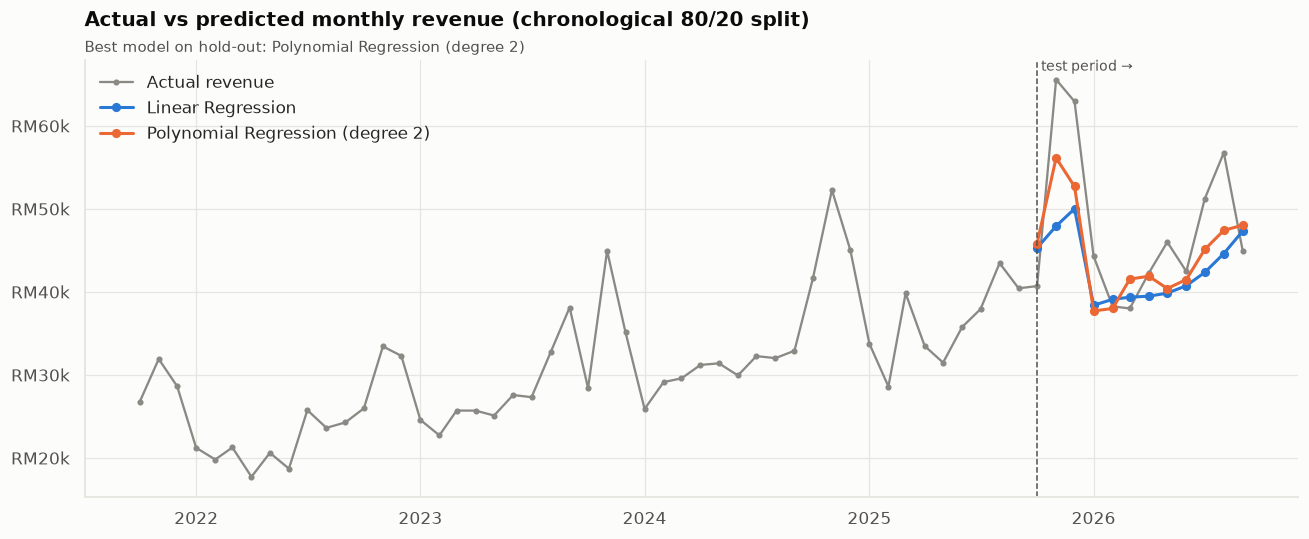

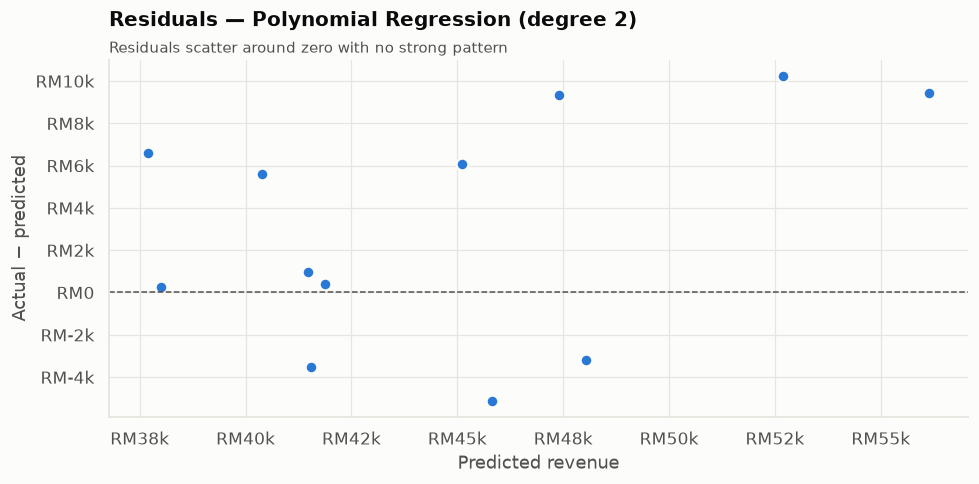

In [15]:
plots.actual_vs_predicted(monthly, comparison)
plots.residuals(comparison)
print("Selected model:", comparison.best_name)

The polynomial model wins on every metric (lower MAE/RMSE, higher R²) because it follows the Q4 peak more closely. Both models **under-predict extreme mega-sale months** — with only 60 monthly points, that is an expected limitation.

## 7. Next 12-Month Revenue Forecast

The selected model is refitted on all 60 months and projected forward.

Forecast total: RM686,739


,MonthStart,Forecast_Revenue
0,2026-10-01,"55,983.93"
1,2026-11-01,"71,839.18"
2,2026-12-01,"70,457.19"
3,2027-01-01,"48,481.41"
4,2027-02-01,"48,758.33"
5,2027-03-01,"52,189.60"
6,2027-04-01,"53,713.88"
7,2027-05-01,"52,432.24"
8,2027-06-01,"53,291.81"
9,2027-07-01,"57,635.01"


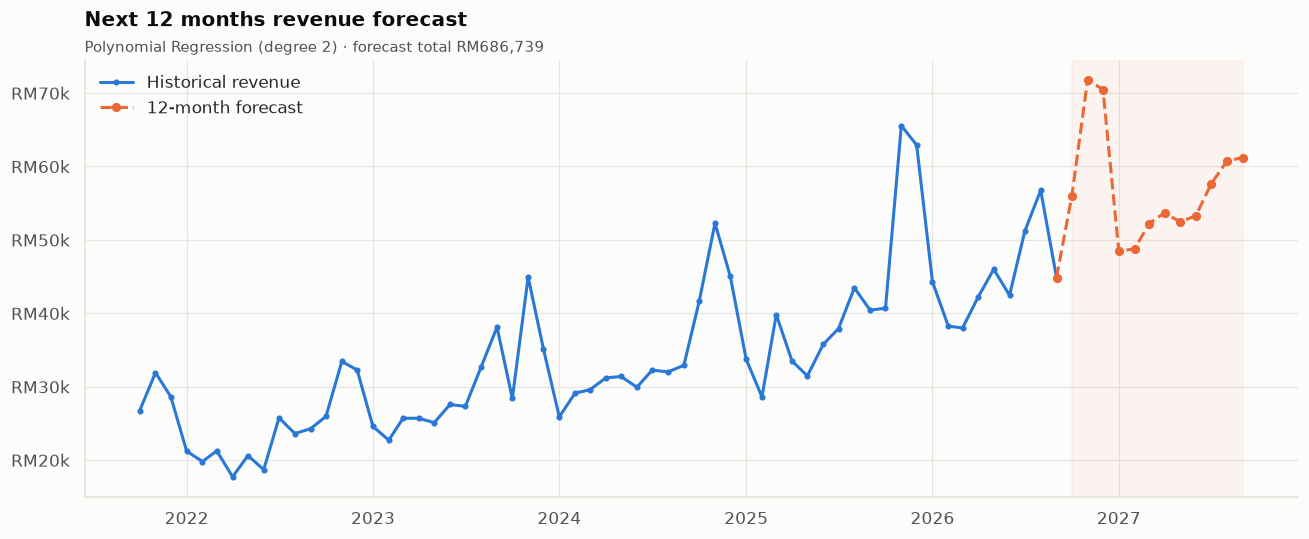

In [16]:
forecast = forecast_next_months(monthly, comparison.best_name, periods=12)
plots.forecast_chart(monthly, forecast, comparison.best_name)
print(f"Forecast total: RM{forecast['Forecast_Revenue'].sum():,.0f}")
forecast

## 8. Key Insights & Recommendations

| # | Insight | Recommendation |
|---|---|---|
| 1 | **Q4 = ~29% of annual revenue**; Nov–Dec are peak months | Lock in inventory & courier capacity by September; plan campaigns around 10.10 / 11.11 / 12.12 |
| 2 | **Mega-sale margin ~25% vs ~37%** on normal days | Use mega-sales for acquisition, but bundle high-margin accessories to protect profit |
| 3 | **Late delivery ≈ −1.2 stars** (2.99 vs 4.20) | Add courier SLAs; route peak-season orders to the best-performing courier |
| 4 | **~35% of orders between 19:00–23:00** | Schedule push notifications, flash deals and ads for the evening window |
| 5 | **E-wallet share rising**, COD falling | Partner with e-wallet providers for cashback; gradually reduce COD cost exposure |
| 6 | **Small Electronics = 34% of sales but lowest margin** | Cross-sell Phone Accessories / Office Supplies (42–44% margin) at checkout |
| 7 | **Repeat-customer rate only ~24.5%** | Launch a loyalty / points programme targeted at first-time buyers |

### Limitations
- The dataset is **synthetic** — patterns illustrate the workflow, not real Malaysian consumer behaviour.
- It is a stored CSV, not a live stream; *velocity* is demonstrated through timestamp-level analysis.
- 60 monthly points is a small sample for ML; the forecast is a **model-based estimate**, not a guarantee.
- Missing ratings are left as missing, so rating KPIs describe *rated* orders only.